# 베버리지 곡선: 미국 노동시장은 얼마나 뜨거운가?

**박기영 (연세대 경제학부)** · 『금융경제학: 파이썬을 활용한 금융시장과 통화정책의 이해』(시그마프레스) 18장 내용을 발표용으로 정리한 노트북입니다.

<a href="https://colab.research.google.com/github/FinancialEconomicsPython/resources/blob/main/talks/beveridge/beveridge_curve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

## 이 노트북 사용법 (3단계)

**1단계 — 로그인**
화면 오른쪽 위의 **로그인** 버튼을 눌러 Google 계정으로 로그인합니다. (Colab에서 코드를 실행하려면 Google 계정이 필요합니다. 읽기만 할 때는 필요 없습니다.)

**2단계 — 전체 실행**
위쪽 메뉴에서 **런타임 → 모두 실행** 을 누릅니다. (단축키: `Ctrl+F9`, Mac은 `⌘+F9`)
- "경고: 이 노트북은 Google에서 작성하지 않았습니다" 창이 뜨면 **무시하고 계속하기** 를 누르세요.
  이 노트북은 공개 데이터(미국 세인트루이스 연준 FRED)를 내려받아 그림을 그리기만 하며, **내 Google 드라이브나 개인정보에는 접근하지 않습니다.**
- 처음 실행에는 30초~1분 정도 걸립니다 (Colab 서버 연결 + 한글 글꼴 설치).

**3단계 — 기간을 바꿔서 다시 그려 보기**
아래 **② 분석 설정** 칸의 입력란에서 기간(예: `2001-01` → `2015-01`)을 바꾼 뒤, 다시 **런타임 → 모두 실행** 을 누르면 그림이 새 기간으로 다시 그려집니다.

> 💾 **내 버전으로 저장하려면:** 메뉴 **파일 → Drive에 사본 저장** 을 누르세요. 내 Google 드라이브의 `Colab Notebooks` 폴더에 복사본이 생기고, 이후 수정 내용은 그 복사본에 저장됩니다. (저장하지 않고 창을 닫으면 바꾼 내용이 사라집니다. 원본은 어떤 경우에도 바뀌지 않으니 마음껏 고쳐 보셔도 됩니다.)
>
> 📱 휴대폰에서도 실행은 되지만, 입력란 수정이 편한 노트북·PC를 권합니다.


## 베버리지 곡선이란?

**가로축 = 실업률(일자리를 찾는 사람의 비율), 세로축 = 빈일자리율(사람을 찾는 일자리의 비율)** 을 찍은 그림입니다.

- **곡선 위의 움직임 = 경기순환.** 경기가 좋으면 기업이 사람을 많이 뽑으려 해 빈일자리율이 오르고 실업률은 내려갑니다(왼쪽 위로 이동). 침체기에는 반대(오른쪽 아래로 이동)입니다.
- **곡선 자체의 이동 = 구인·구직 연결(매칭) 효율의 변화.** 같은 실업률에서도 빈일자리가 더 많다면(곡선이 바깥으로 이동), 일자리와 구직자가 잘 연결되지 않고 있다는 뜻입니다. GFC 이후와 팬데믹 이후에 곡선이 바깥쪽으로 이동했습니다.
- **통화정책과의 연결.** 2022년 연준 긴축 당시 "빈일자리율이 높은 지금은 실업률을 크게 올리지 않고도 노동수요를 식힐 수 있다"(Figura & Waller, 2022)는 견해와 "역사적으로 그런 연착륙은 드물다"(Blanchard, Domash & Summers, 2022)는 견해가 맞섰습니다. 이후 실제 데이터가 어느 쪽에 가까웠는지 아래 그림에서 확인해 보세요.

**데이터 (모두 FRED에서 API 키 없이 무료로 받음)**

| 변수 | FRED 코드 | 설명 |
|---|---|---|
| 실업률 | `UNRATE` | 실업자 ÷ 경제활동인구 (%, 월별, 계절조정) |
| 빈일자리율 | `JTSJOR` | 빈일자리 ÷ (취업자 + 빈일자리) (%, JOLTS 조사, **2000년 12월부터**) |
| 빈일자리 수 / 실업자 수 | `JTSJOL`, `UNEMPLOY` | 노동시장 과열도(V/U 비율) 계산용 (천 명) |
| 경기침체 구간 | `USREC` | NBER 기준 경기침체기 = 1 |


In [ ]:
#@title ① 준비 (패키지·한글 글꼴) — 수정할 필요 없습니다
import sys, io, subprocess, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

IN_COLAB = "google.colab" in sys.modules

# 그래프 한글 표시: Colab은 koreanize-matplotlib 설치, 내 PC는 운영체제의 한글 글꼴 사용
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    if IN_COLAB:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"], check=False)
        import koreanize_matplotlib  # noqa: F401
    else:
        from matplotlib import font_manager
        installed = {f.name for f in font_manager.fontManager.ttflist}
        for name in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
            if name in installed:
                plt.rcParams["font.family"] = name
                break
plt.rcParams["axes.unicode_minus"] = False

# 그림 기본 스타일 (옅은 격자, 위·오른쪽 테두리 제거)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "legend.frameon": False,
})
print("✅ 준비 완료")


✅ 준비 완료


In [ ]:
#@title ② 분석 설정 — 여기만 바꾸고 다시 실행하세요
#@markdown **표본기간** (형식: `YYYY-MM`. 빈일자리율 데이터는 `2000-12`부터 있습니다. 끝을 `latest`로 두면 최신 달까지)
START = "2001-01"  #@param {type:"string"}
END = "latest"  #@param {type:"string"}

#@markdown **구간 나누기** (그림 2의 색깔 구분)
GFC_START = "2008-01"  #@param {type:"string"}
GFC_END = "2009-07"  #@param {type:"string"}
COVID_START = "2020-04"  #@param {type:"string"}

#@markdown **데이터 출처** (`FRED` = 실시간 최신 데이터, `snapshot` = 저장된 사본. FRED 접속이 안 되면 자동으로 snapshot 사용)
DATA_SOURCE = "FRED"  #@param ["FRED", "snapshot"]


In [ ]:
#@title ③ 데이터 불러오기
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=UNRATE,JTSJOR,JTSJOL,UNEMPLOY,USREC"
SNAPSHOT_URL = "https://raw.githubusercontent.com/FinancialEconomicsPython/resources/main/talks/beveridge/beveridge_snapshot.csv"
SNAPSHOT_LOCAL = "beveridge_snapshot.csv"   # 내 PC에서 노트북과 같은 폴더에 있을 때


def read_csv_any(src, timeout=20):
    """URL이면 시간제한을 두고 내려받고, 아니면 파일로 읽는다."""
    if src.startswith("http"):
        with urllib.request.urlopen(src, timeout=timeout) as r:
            src = io.StringIO(r.read().decode("utf-8"))
    df = pd.read_csv(src, index_col=0, parse_dates=True)
    df.index.name = "date"
    return df.rename(columns={"UNRATE": "unrate", "JTSJOR": "vacancy",
                              "JTSJOL": "openings", "UNEMPLOY": "unemployed",
                              "USREC": "recession"})


def load_data(source):
    if source == "FRED":
        try:
            return read_csv_any(FRED_URL), "FRED (실시간)"
        except Exception as e:
            print(f"⚠️ FRED 접속 실패 ({type(e).__name__}) → 저장된 스냅샷으로 대신합니다.")
    for src in (SNAPSHOT_LOCAL, SNAPSHOT_URL):
        try:
            return read_csv_any(src), f"스냅샷 ({src.split('/')[-1]})"
        except Exception:
            pass
    raise RuntimeError("데이터를 불러오지 못했습니다. 인터넷 연결을 확인해 주세요.")


raw, source_used = load_data(DATA_SOURCE)

end = raw.index.max() if END.strip().lower() in ("", "latest") else END
df = raw.loc[START:end]
bc = df.dropna(subset=["unrate", "vacancy"])          # 베버리지 곡선용 (두 변수 모두 있는 달)

if pd.Timestamp(START) < pd.Timestamp("2000-12"):
    print("ℹ️ 빈일자리율(JOLTS)은 2000년 12월부터 있어서, 그 이전은 그림에서 빠집니다.")
print(f"데이터: {source_used}")
print(f"표본기간: {bc.index[0]:%Y-%m} ~ {bc.index[-1]:%Y-%m} ({len(bc)}개월)")
bc[["unrate", "vacancy"]].tail()


데이터: FRED (실시간)
표본기간: 2001-01 ~ 2026-08 (307개월)


,unrate,vacancy
date,,
2026-04-01,4.3,4.6
2026-05-01,4.3,4.5
2026-06-01,4.2,4.3
2026-07-01,4.1,4.4
2026-08-01,4.1,4.3


In [ ]:
#@title 공통 함수 (구간 정의 · 경기침체 음영)
def shift_month(ym, k):
    """'YYYY-MM' 문자열을 k개월 이동."""
    return (pd.Period(ym, "M") + k).strftime("%Y-%m")


LAST = f"{bc.index[-1]:%Y-%m}"
PERIODS = {                                   # 이름: (시작, 끝)
    "GFC 이전":    (START,                     shift_month(GFC_START, -1)),
    "GFC":         (GFC_START,                 GFC_END),
    "GFC 이후":    (shift_month(GFC_END, 1),   shift_month(COVID_START, -1)),
    "팬데믹 이후": (COVID_START,               LAST),
}
# 구간마다 색 + 모양을 함께 달리함 (색각이상·흑백 인쇄에서도 구분되도록)
STYLES = {
    "GFC 이전":    dict(color="#2a78d6", marker="o"),
    "GFC":         dict(color="#eb6834", marker="s"),
    "GFC 이후":    dict(color="#1baf7a", marker="^"),
    "팬데믹 이후": dict(color="#eda100", marker="D"),
}


def shade_recessions(ax, rec):
    """USREC = 1 인 구간을 회색 음영으로 표시."""
    rec = rec.fillna(0).astype(int)
    starts = rec.index[(rec == 1) & (rec.shift(1, fill_value=0) == 0)]
    ends = rec.index[(rec == 1) & (rec.shift(-1, fill_value=0) == 0)]
    for s, e in zip(starts, ends):
        ax.axvspan(s, e + pd.offsets.MonthEnd(0), color="0.85", lw=0, zorder=0)


def mark_last(ax, x, y, text):
    """마지막 관측치를 검은 테두리로 강조하고, 비어 있는 아래쪽에 날짜 표시."""
    ax.scatter([x], [y], s=110, facecolors="none", edgecolors="black", linewidths=1.2, zorder=5)
    ax.annotate(text, xy=(x, y), xytext=(-10, -90), textcoords="offset points",
                fontsize=9, color="0.2", ha="left",
                arrowprops=dict(arrowstyle="-", lw=0.6, color="0.4"))


## 그림 1. 실업률과 빈일자리율의 추이

회색 음영은 NBER 기준 경기침체기입니다. 침체기마다 실업률은 치솟고 빈일자리율은 떨어집니다. 두 선이 서로 반대로 움직이는 이 관계를 한 장의 산점도로 옮긴 것이 베버리지 곡선입니다.

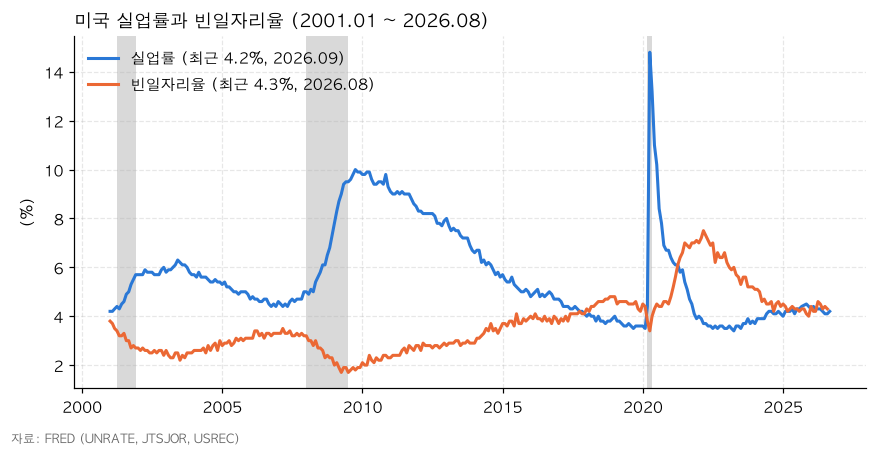

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
shade_recessions(ax, df["recession"])
# 범례에 최근 값을 함께 표시
for col, name, c in [("unrate", "실업률", "#2a78d6"), ("vacancy", "빈일자리율", "#eb6834")]:
    s = df[col].dropna()
    ax.plot(s.index, s, color=c, lw=2, label=f"{name} (최근 {s.iloc[-1]:.1f}%, {s.index[-1]:%Y.%m})")

ax.set_ylabel("(%)")
ax.set_title(f"미국 실업률과 빈일자리율 ({bc.index[0]:%Y.%m} ~ {bc.index[-1]:%Y.%m})", loc="left")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, -0.02, "자료: FRED (UNRATE, JTSJOR, USREC)", fontsize=8, color="0.4")
plt.tight_layout()
plt.show()


## 그림 2. 베버리지 곡선 — 시기별 비교

같은 실업률에서 점들이 더 위쪽에 찍힌다면 곡선이 바깥으로 이동한 것입니다. **② 분석 설정** 에서 구간 경계(`GFC_START`, `COVID_START` 등)를 바꾸면 색깔 구분이 따라 바뀝니다.

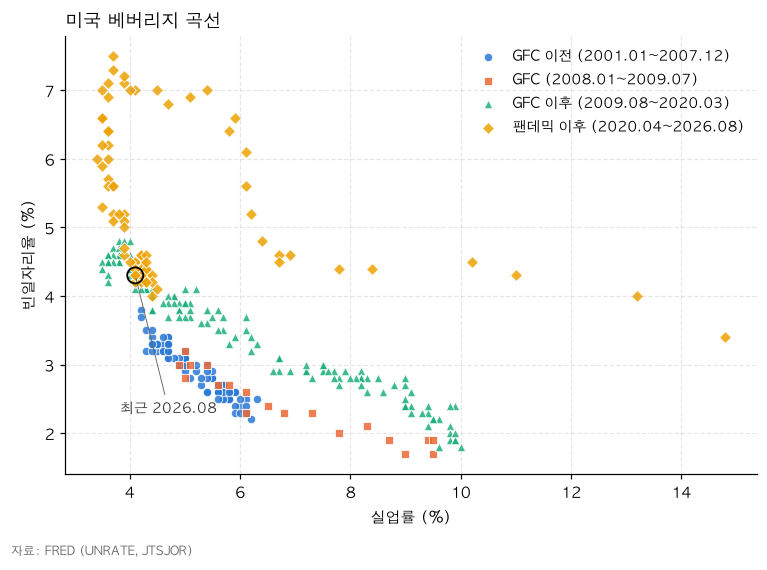

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, (s, e) in PERIODS.items():
    part = bc.loc[s:e]
    if part.empty:            # 표본기간 밖의 구간은 건너뜀
        continue
    ax.scatter(part["unrate"], part["vacancy"], s=30, alpha=0.85,
               edgecolors="white", linewidths=0.6,
               label=f"{name} ({part.index[0]:%Y.%m}~{part.index[-1]:%Y.%m})", **STYLES[name])

last = bc.iloc[-1]
mark_last(ax, last["unrate"], last["vacancy"], f"최근 {bc.index[-1]:%Y.%m}")

ax.set_xlabel("실업률 (%)")
ax.set_ylabel("빈일자리율 (%)")
ax.set_title("미국 베버리지 곡선", loc="left")
ax.legend(loc="upper right", fontsize=9)
fig.text(0.01, -0.02, "자료: FRED (UNRATE, JTSJOR)", fontsize=8, color="0.4")
plt.tight_layout()
plt.show()


## 그림 3. 베버리지 곡선 — 시간의 흐름

옅은 색이 과거, 진한 색이 최근입니다. 점을 시간 순서로 이은 회색 선을 따라가면, 팬데믹 직후 실업률이 급등했다가 빈일자리율이 치솟는 경로로 회복한 뒤, 긴축기에 빈일자리율이 내려온 과정을 볼 수 있습니다.

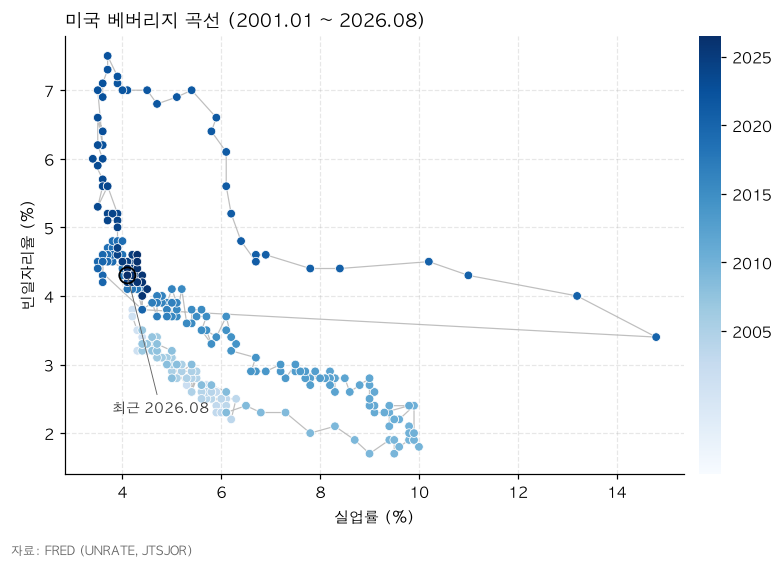

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 5))
t = np.arange(len(bc))
ax.plot(bc["unrate"], bc["vacancy"], color="0.75", lw=0.8, zorder=1)
sc = ax.scatter(bc["unrate"], bc["vacancy"], c=t, cmap="Blues", vmin=-0.25 * len(bc),
                s=32, edgecolors="white", linewidths=0.5, zorder=2)

# 색 막대에 연도 표시 (5년 간격)
cbar = fig.colorbar(sc, ax=ax, pad=0.02)
years = range((bc.index[0].year // 5 + 1) * 5, bc.index[-1].year + 1, 5)
pos = bc.index.get_indexer(pd.to_datetime([f"{y}-01-01" for y in years]), method="nearest")
cbar.set_ticks(pos)
cbar.set_ticklabels([str(y) for y in years])
cbar.outline.set_visible(False)

last = bc.iloc[-1]
mark_last(ax, last["unrate"], last["vacancy"], f"최근 {bc.index[-1]:%Y.%m}")

ax.set_xlabel("실업률 (%)")
ax.set_ylabel("빈일자리율 (%)")
ax.set_title(f"미국 베버리지 곡선 ({bc.index[0]:%Y.%m} ~ {bc.index[-1]:%Y.%m})", loc="left")
fig.text(0.01, -0.02, "자료: FRED (UNRATE, JTSJOR)", fontsize=8, color="0.4")
plt.tight_layout()
plt.show()


## 그림 4. 노동시장 과열도: 빈일자리 수 ÷ 실업자 수 (V/U 비율)

파월 의장이 노동시장의 수급 상황을 설명할 때 자주 언급한 지표입니다. **1보다 크면 실업자 한 명당 빈일자리가 한 개 이상** 있다는 뜻으로, 노동수요가 공급보다 강하다는 신호입니다.

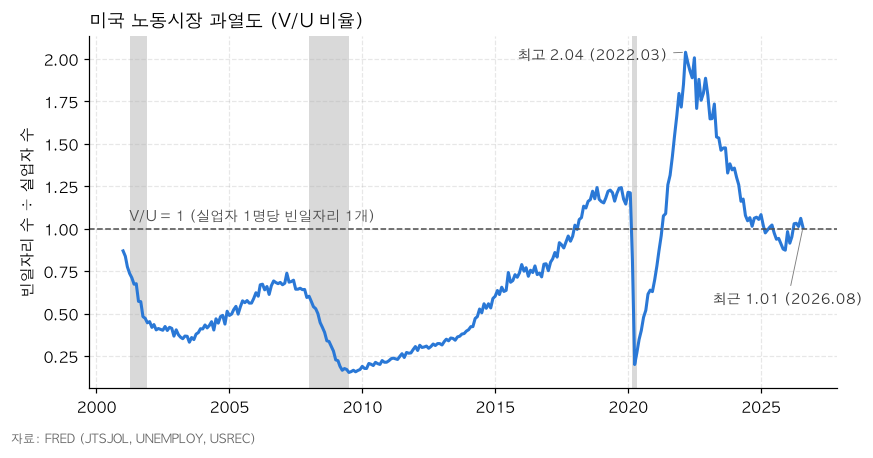

In [ ]:
vu = (df["openings"] / df["unemployed"]).dropna()

fig, ax = plt.subplots(figsize=(8, 4))
shade_recessions(ax, df["recession"])
ax.plot(vu.index, vu, color="#2a78d6", lw=2)
ax.axhline(1, color="0.3", lw=1, ls="--")
ax.annotate("V/U = 1 (실업자 1명당 빈일자리 1개)", xy=(vu.index[0], 1), xytext=(4, 5),
            textcoords="offset points", fontsize=9, color="0.3")

peak_date = vu.idxmax()
ax.annotate(f"최고 {vu.max():.2f} ({peak_date:%Y.%m})", xy=(peak_date, vu.max()), xytext=(-110, -5),
            textcoords="offset points", fontsize=9, color="0.2",
            arrowprops=dict(arrowstyle="-", lw=0.6, color="0.5"))
ax.annotate(f"최근 {vu.iloc[-1]:.2f} ({vu.index[-1]:%Y.%m})", xy=(vu.index[-1], vu.iloc[-1]), xytext=(-10, -50),
            textcoords="offset points", fontsize=9, color="0.2", ha="center",
            arrowprops=dict(arrowstyle="-", lw=0.6, color="0.5"))

ax.set_ylabel("빈일자리 수 ÷ 실업자 수")
ax.set_title("미국 노동시장 과열도 (V/U 비율)", loc="left")
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.text(0.01, -0.02, "자료: FRED (JTSJOL, UNEMPLOY, USREC)", fontsize=8, color="0.4")
plt.tight_layout()
plt.show()


## 직접 해 보기

**② 분석 설정** 에서 아래처럼 바꾸고 **런타임 → 모두 실행** 을 눌러 보세요.

1. **팬데믹을 빼고 보기:** `END` 를 `2019-12` 로 → 팬데믹 전까지 곡선이 얼마나 안정적이었나?
2. **최근만 확대해서 보기:** `START` 를 `2019-01` 로 → 긴축기에 점들이 어느 방향으로 움직였나? (빈일자리율만 내려왔나, 실업률도 올랐나?)
3. **구간 다시 나누기:** `COVID_START` 를 `2022-03` (연준 첫 금리 인상)으로 → 긴축 전후의 비교

## 더 읽을거리

- ["베버리지 곡선은 노동시장의 회복상에 대해 무엇을 말해 주는가?"](https://www.stlouisfed.org/on-the-economy/2022/jul/beveridge-curve-labor-market-recovery) (세인트루이스 연준 블로그, 2022.7)
- ["최근 베버리지 곡선은 왜 급격하게 이동했는가?"](https://www.richmondfed.org/publications/research/economic_brief/2021/eb_21-36) (리치몬드 연준 Economic Brief, 2021.10)
- ["베버리지 곡선을 통한 노동시장 평가: 미국과의 비교를 중심으로"](https://www.bok.or.kr/portal/bbs/B0000347/view.do?nttId=10072542&menuNo=201106) (한국은행 블로그, 2022.8)

---

📘 더 많은 그림과 분석: 『금융경제학: 파이썬을 활용한 금융시장과 통화정책의 이해』(박기영, 시그마프레스)
· 전체 코드: [github.com/FinancialEconomicsPython/resources](https://github.com/FinancialEconomicsPython/resources)
· 문의: financialeconomicspython@gmail.com
